In [1]:
import os
import cv2
import argparse
from ultralytics  import YOLO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from analyze_errors.matching import match_gt_with_results
from analyze_errors.metrics_calculate import compute_map, box_metrics_calculate, frame_level_metrics, compute_map_coco_style
from analyze_errors.visualization import visualize_prediction
from analyze_errors.eigen_cam import EigenCAM, visualize_prediction_with_cam, only_eigencam_visualizate

# === parameters ===
RANDOM_STATE = 42

In [2]:
# === parameters ===
path2data_file = "./data_overfit.yaml"
split = "val"
path2model = "runs/detect/baseline_v0/overfiting_test_2/weights/best.pt"
imgsize = 512
project = "baseline_v0"
exp_name = "errors_analyze_overfitting"
conf = 0.001

nms_iou = 0.6
match_iou = 0.5

batch_size = 32

In [3]:
# === model init ===
model = YOLO(path2model)

In [4]:
results = model.predict(
    source="./dataset_yolo/overfitting.txt",
    imgsz=imgsize,
    batch=batch_size,
    workers=2,
    seed=RANDOM_STATE,
    deterministic=True,
    conf=conf, # 0.0001 # низкий порог для честного расчёта mAP
    iou=nms_iou, # IoU для NMS при валидации
    verbose=False # Отключить печать
)

In [5]:
eigencam = EigenCAM(model, target_layer_idx=15)   # P5; для мелких объектов попробуй 15 (P3)

### mAP calculate

In [6]:
m = compute_map(results, "./dataset_yolo/labels", num_classes=1)
print(f"mAP0.5: {m['map_05']:0.4f}")
print(f"mAP0.5-0.95: {m['map_50_95']:.4f}")
print(m)

mAP0.5: 0.9950
mAP0.5-0.95: 0.9950
{'ap_table': array([[      0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995]]), 'map_05': 0.995, 'map_50_95': 0.9949999999999999, 'per_iou_map': {0.5: 0.995, 0.55: 0.995, 0.6000000000000001: 0.995, 0.6500000000000001: 0.995, 0.7000000000000002: 0.995, 0.7500000000000002: 0.995, 0.8000000000000003: 0.995, 0.8500000000000003: 0.995, 0.9000000000000004: 0.995, 0.9500000000000004: 0.995}, 'per_class_ap_05': {0: 0.995}}


In [8]:
coco_m = compute_map_coco_style(results, "./dataset_yolo/labels", num_classes=1)
print(f"mAP0.5: {coco_m['map_05']}")
print(f"mAP0.5-0.95: {coco_m['map_50_95']}")
print(coco_m)

mAP0.5: 0.9950000047683716
mAP0.5-0.95: 0.9950000047683716
{'ap_table': array([[      0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995,       0.995]], dtype=float32), 'map_05': 0.9950000047683716, 'map_50_95': 0.9950000047683716, 'per_iou_map': {0.5: 0.9950000047683716, 0.550000011920929: 0.9950000047683716, 0.6000000238418579: 0.9950000047683716, 0.6499999761581421: 0.9950000047683716, 0.699999988079071: 0.9950000047683716, 0.75: 0.9950000047683716, 0.800000011920929: 0.9950000047683716, 0.8500000238418579: 0.9950000047683716, 0.8999999761581421: 0.9950000047683716, 0.949999988079071: 0.9950000047683716}, 'per_class_ap_05': {0: 0.9950000047683716}, 'gt_count': array([56])}


In [11]:
frame_m = frame_level_metrics(results, "./dataset_yolo/labels")
for item in frame_m:
    print(f"{item}: {frame_m[item]:.4f}")

sensitivity: 1.0000
specificity: 1.0000
precision: 1.0000
recall: 1.0000
f1: 1.0000
accuracy: 1.0000
tp: 25.0000
fp: 0.0000
fn: 0.0000
tn: 25.0000


### TP, FP, FN, Precision, Recall for GT

In [12]:
boxes_metrics = []
for c in np.linspace(0.05, 0.9, 18):
    m = box_metrics_calculate(results, "./dataset_yolo/labels", iou=match_iou, conf=c)
    boxes_metrics.append({
        "conf": c,
        "iou": match_iou,
        "metrics": m 
    })

In [13]:
for item in boxes_metrics:
    ii = item['metrics']
    print(f"conf: {item['conf']:.2f}, | TP: {ii['TP']} | FP: {ii['FP']} | FN: {ii['FN']} | P: {ii['P']:.4f} R: {ii['R']:.4f} | F1: {ii['F1']:.4f}")

conf: 0.05, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.10, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.15, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.20, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.25, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.30, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.35, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.40, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.45, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.50, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.55, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.60, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.65, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1: 1.0000
conf: 0.70, | TP: 56 | FP: 0 | FN: 0 | P: 1.0000 R: 1.0000 | F1:

### Visualization

In [49]:
result_item = results[5]
stem = result_item.path.split("\\")[-1].split('.')[0]
path2label = f"./dataset_yolo/labels/{stem}.txt"

# un_gt - idx для FN (из GT) - то есть можно сопоставить с теми, которые не были найдены
matches, un_gt, un_pred, gt = match_gt_with_results(
    result_item, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

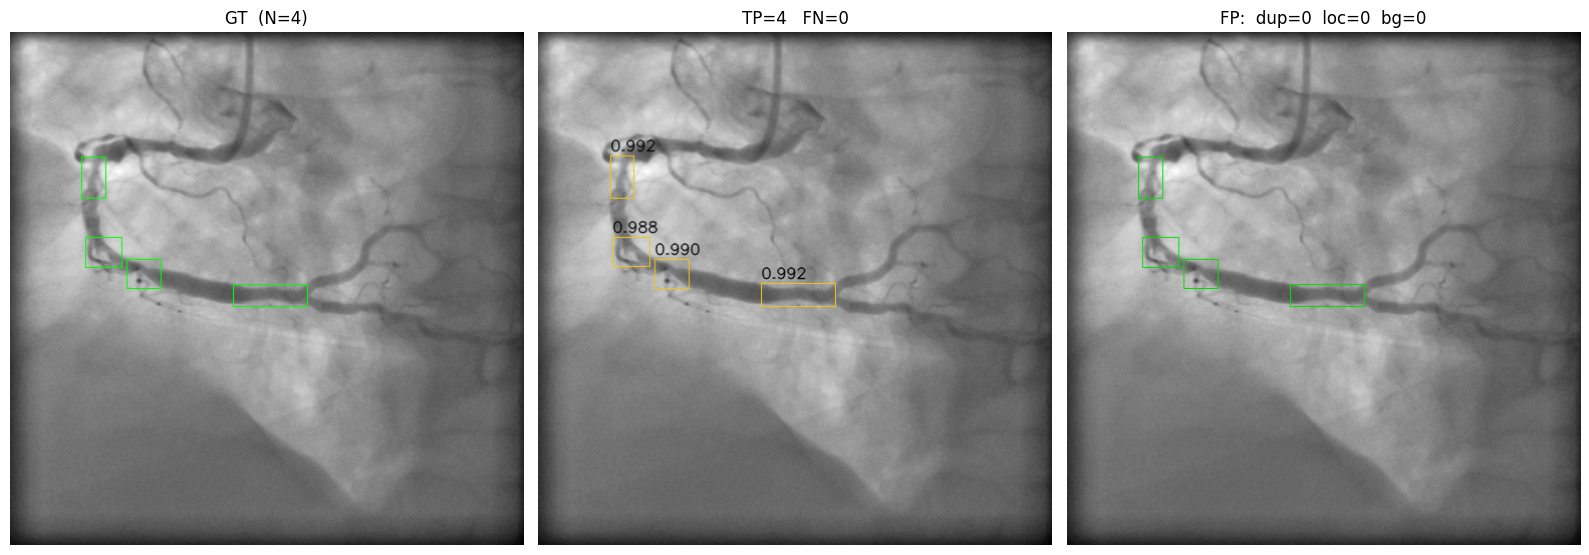

In [50]:
visualize_prediction(
    result_item, matches, un_gt, un_pred, gt
)

### EigenCAM visualization

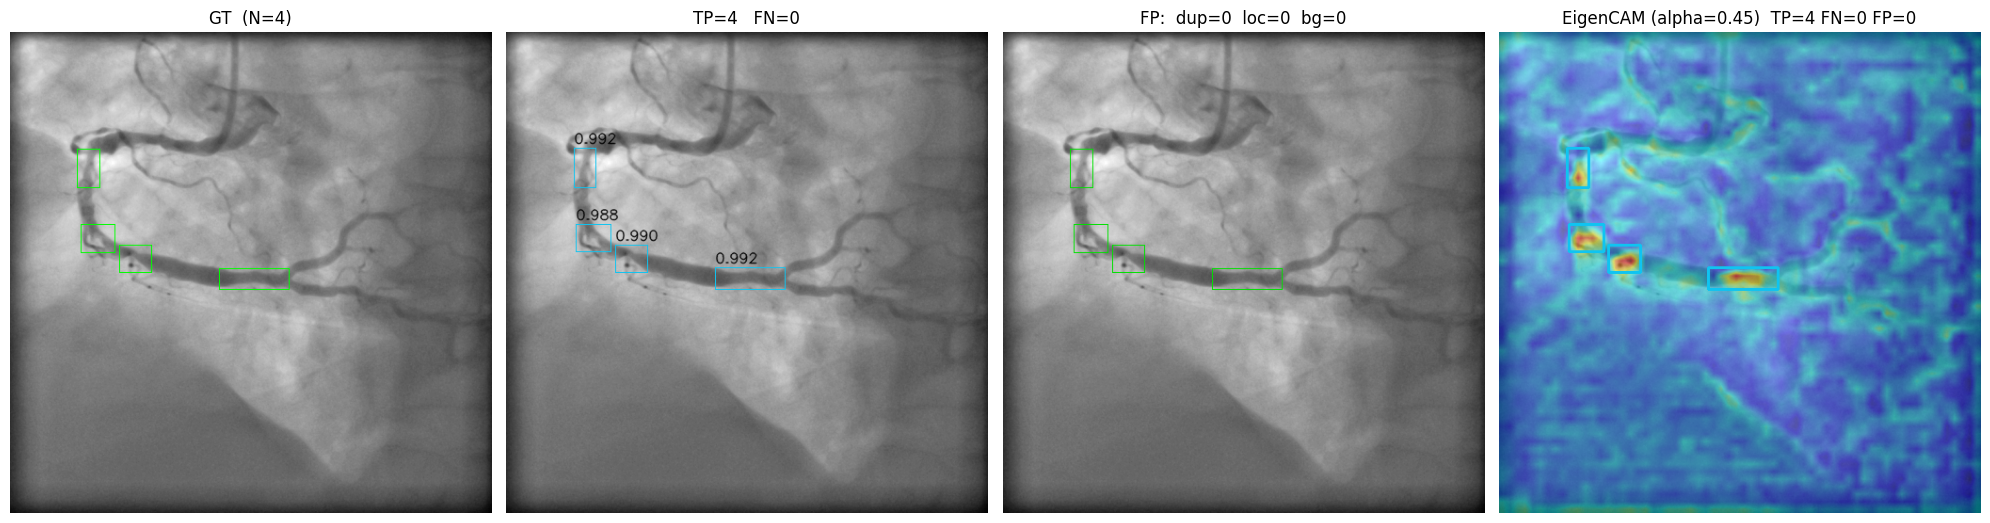

In [51]:
result_cam, heatmap, feat_shape = eigencam(result_item.path, imgsz=imgsize)

matches, un_gt, un_pred, gt = match_gt_with_results(
    result_cam, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

visualize_prediction_with_cam(result_cam, matches, un_gt, un_pred, gt, heatmap, alpha=0.45, figsize=(20, 15))

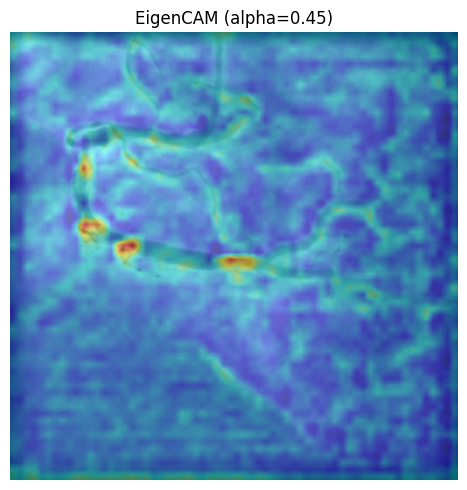

In [58]:
only_eigencam_visualizate(result_cam, heatmap, alpha=0.45, figsize=(9, 5))